In [220]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

import pymc as pm
import arviz as az
import trace

from scipy.stats import bootstrap, permutation_test

In [ ]:
# СТОХАСТИКА
# │
# ├── 1. ТЕОРІЯ ЙМОВІРНОСТЕЙ
# │   │
# │   ├── Випадкові події
# │   ├── Умовна ймовірність
# │   ├── Незалежність
# │   ├── Теорема Баєса
# │   │
# │   ├── Випадкові величини
# │   │   ├── Дискретні
# │   │   └── Неперервні
# │   │
# │   ├── Основні розподіли
# │   │   ├── Bernoulli
# │   │   ├── Binomial
# │   │   ├── Poisson
# │   │   ├── Normal
# │   │   ├── Exponential
# │   │   ├── Uniform
# │   │   ├── Geometric
# │   │   ├── Beta
# │   │   └── Gamma
# │   │
# │   ├── Математичне сподівання
# │   ├── Дисперсія
# │   ├── Коваріація
# │   ├── Кореляція
# │   │
# │   ├── Закон великих чисел
# │   └── Центральна гранична теорема
# │
# │
# ├── 2. МАТЕМАТИЧНА СТАТИСТИКА
# │   │
# │   ├── 2.1 Частотна статистика
# │   │   │
# │   │   ├── Оцінювання параметрів
# │   │   │   ├── MLE
# │   │   │   ├── Method of Moments
# │   │   │   └── Point Estimation
# │   │   │
# │   │   ├── Confidence Intervals
# │   │   ├── Hypothesis Testing
# │   │   │   ├── p-value
# │   │   │   ├── Type I / Type II errors
# │   │   │   ├── t-test
# │   │   │   ├── z-test
# │   │   │   ├── Chi-square test
# │   │   │   └── ANOVA
# │   │   │
# │   │   ├── Bootstrap
# │   │   ├── Jackknife
# │   │   └── Permutation Tests
# │   │
# │   └── 2.2 Баєсівська статистика
# │       │
# │       ├── Prior
# │       ├── Likelihood
# │       ├── Posterior
# │       ├── Bayesian Inference
# │       ├── Bayesian Networks
# │       ├── MCMC
# │       │   ├── Metropolis-Hastings
# │       │   └── Gibbs Sampling
# │       └── Bayesian Regression
# │
# │
# ├── 3. СТОХАСТИЧНІ ПРОЦЕСИ
# │   │
# │   ├── Дискретний час
# │   │   │
# │   │   ├── Random Walk
# │   │   ├── Markov Chains
# │   │   │   ├── Discrete Markov Chain
# │   │   │   ├── Transition Matrix
# │   │   │   └── Hidden Markov Model
# │   │   │
# │   │   └── Martingales
# │   │
# │   ├── Неперервний час
# │   │   │
# │   │   ├── Brownian Motion
# │   │   │   └── Wiener Process
# │   │   │
# │   │   ├── Poisson Process
# │   │   ├── Continuous-time Markov Chains
# │   │   └── Stochastic Differential Equations
# │   │
# │   └── Фінансові стохастичні процеси
# │       │
# │       ├── Geometric Brownian Motion
# │       ├── Mean Reversion
# │       ├── Ornstein-Uhlenbeck Process
# │       ├── Stochastic Volatility
# │       └── Jump Diffusion
# │
# │
# ├── 4. СТОХАСТИЧНІ АЛГОРИТМИ
# │   │
# │   ├── Randomized Algorithms
# │   │   ├── Randomized QuickSort
# │   │   └── Randomized Search
# │   │
# │   ├── Sampling
# │   │   ├── Reservoir Sampling
# │   │   ├── Random Sampling
# │   │   └── Importance Sampling
# │   │
# │   ├── Monte Carlo Methods
# │   │   ├── Monte Carlo Simulation
# │   │   ├── Monte Carlo Integration
# │   │   └── Monte Carlo Optimization
# │   │
# │   ├── Optimization
# │   │   ├── SGD
# │   │   ├── Mini-batch SGD
# │   │   ├── Simulated Annealing
# │   │   └── Stochastic Optimization
# │   │
# │   └── Evolutionary Algorithms
# │       ├── Genetic Algorithms
# │       ├── Genetic Programming
# │       └── Evolution Strategies
# │
# │
# └── 5. СТОХАСТИКА В MACHINE LEARNING
#     │
#     ├── Ensemble Methods
#     │   ├── Bagging
#     │   ├── Random Forest
#     │   └── Randomized Trees
#     │
#     ├── Neural Networks
#     │   ├── SGD
#     │   ├── Mini-batch Training
#     │   ├── Dropout
#     │   └── Bayesian Neural Networks
#     │
#     ├── Probabilistic ML
#     │   ├── Naive Bayes
#     │   ├── Bayesian Networks
#     │   ├── Gaussian Processes
#     │   └── Probabilistic Graphical Models
#     │
#     └── Reinforcement Learning
#         ├── Markov Decision Processes
#         ├── Monte Carlo Methods
#         ├── Temporal Difference Learning
#         └── Multi-Armed Bandits

# числові значення

In [221]:
def bayesian_ab_test_numeric(
    y0,
    y1,
    draws=2000,
    tune=1000,
    chains=4,
    target_accept=0.9,
    log_transform=False,
):
    if log_transform:
        y0 = np.log(y0)
        y1 = np.log(y1)

    y_combined = np.concatenate([y0, y1])
    mu_mean = np.mean(y_combined)
    mu_std = np.std(y_combined)

    with pm.Model() as model:
        mu0 = pm.Normal("mu0", mu=mu_mean, sigma=10 * mu_std)
        mu1 = pm.Normal("mu1", mu=mu_mean, sigma=10 * mu_std)

        sigma0 = pm.HalfNormal("sigma0", sigma=mu_std)
        sigma1 = pm.HalfNormal("sigma1", sigma=mu_std)

        pm.Normal("likelihood0", mu=mu0, sigma=sigma0, observed=y0)
        pm.Normal("likelihood1", mu=mu1, sigma=sigma1, observed=y1)

        pm.Deterministic("delta", mu1 - mu0)

        trace = pm.sample(
            draws=draws,
            tune=tune,
            chains=chains,
            target_accept=target_accept,
            return_inferencedata=True,
            progressbar=True,
        )

    delta_samples = trace.posterior["delta"].values.flatten()

    pm.plot_posterior(trace, var_names=["mu0", "mu1", "delta"], kind="kde", hdi_prob=0.95)

    return delta_samples, trace

# синтетичні дані

In [223]:
rng = np.random.default_rng(42)

n = 10_000
y = rng.integers(0, 2, size=n)

gross_summ = np.empty(n)

gross_summ[y == 0] = rng.lognormal(mean=3.5, sigma=0.8, size=(y == 0).sum())
gross_summ[y == 1] = rng.lognormal(mean=3.55, sigma=0.8, size=(y == 1).sum())

df = pd.DataFrame({
    "gross_summ": gross_summ,
    "target": y
})

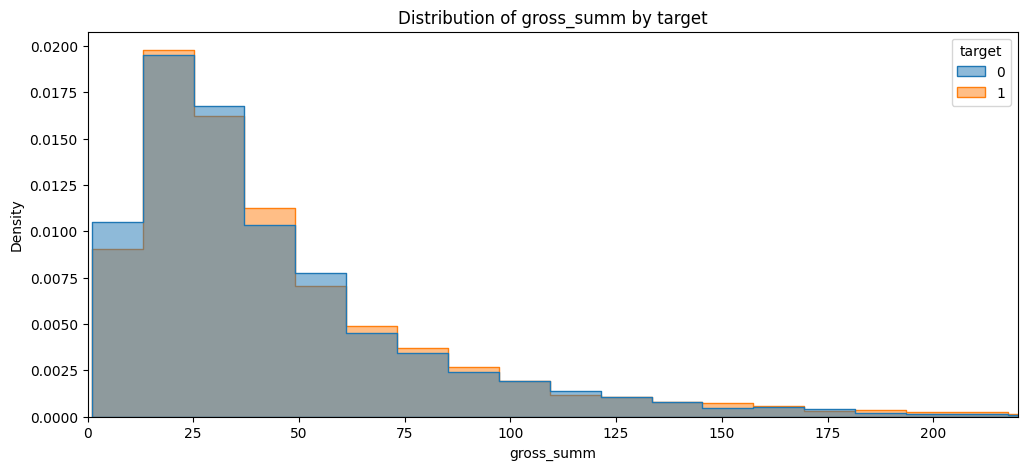

In [224]:
plt.figure(figsize=(12, 5))
sns.histplot(
    data=df,
    x='gross_summ',
    hue='target',
    element='step',
    stat='density',
    common_norm=False,
    bins=80,
    alpha=0.5,
    palette=['tab:blue', 'tab:orange']
)
plt.xlim(0, df['gross_summ'].quantile(0.99))
plt.title('Distribution of gross_summ by target')
plt.xlabel('gross_summ')
plt.ylabel('Density')
plt.show()

In [225]:
df.groupby('target')['gross_summ'].mean(), df.shape

(target
 0    45.899405
 1    47.975608
 Name: gross_summ, dtype: float64,
 (10000, 2))

In [226]:
df_sample = df.sample(frac=0.1)
df_sample.shape

(1000, 2)

In [227]:
df_sample.groupby('target')['gross_summ'].mean()

target
0    47.520304
1    45.402016
Name: gross_summ, dtype: float64

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu0, mu1, sigma0, sigma1]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2 seconds.


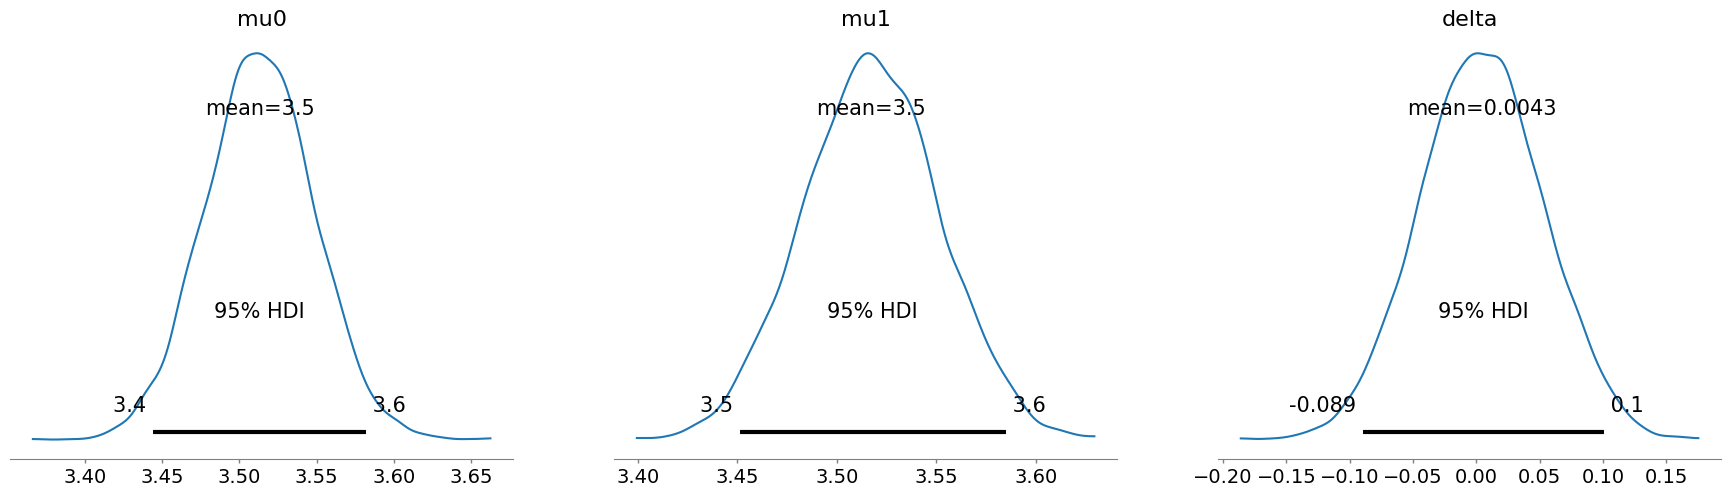

In [228]:
y0 = df_sample[df_sample['target'] == 0]['gross_summ'].values
y1 = df_sample[df_sample['target'] == 1]['gross_summ'].values

delta_samples, trace = bayesian_ab_test_numeric(
    y0=y0,
    y1=y1,
    draws=2000,
    tune=1000,
    chains=4,
    target_accept=0.9,
    log_transform=True
)

Percent 0.53


<Axes: ylabel='Density'>

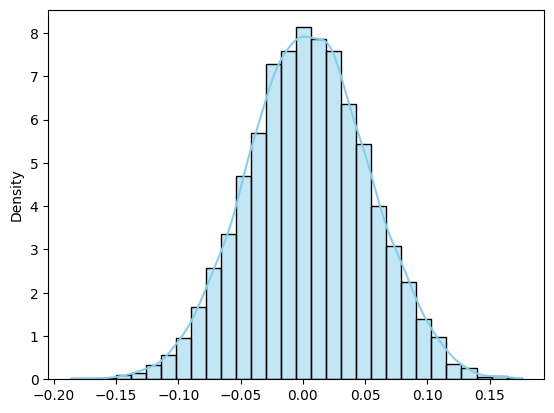

In [229]:
prob_delta_gt_0 = (delta_samples > 0).mean()
print(f"Percent {prob_delta_gt_0:.2}")

sns.histplot(delta_samples, kde=True, stat="density", bins=30, color="skyblue", edgecolor="black")

In [230]:
res = bootstrap(
    (df_sample[df_sample['target']==1]['gross_summ'].values, df_sample[df_sample['target']==0]['gross_summ'].values), 
    statistic=lambda x, y: x.mean() - y.mean(),
    n_resamples=100,
    confidence_level=0.95,
    batch=10
)
res.confidence_interval

ConfidenceInterval(low=np.float64(-10.34964282450643), high=np.float64(2.044990995216273))

In [231]:
res = permutation_test(
    (df_sample.loc[df_sample['target']==1, 'gross_summ'], df_sample.loc[df_sample['target']==0, 'gross_summ']),
    statistic=lambda x, y: x.mean() - y.mean(),
    n_resamples=100,
    alternative='two-sided'
)

res.statistic, res.pvalue

(np.float64(-2.1182882868843933), np.float64(0.4752475247524752))